In [2]:
## use pyPPG 102 features
from pyPPG import PPG, Fiducials, Biomarkers
from pyPPG.datahandling import load_data, plot_fiducials, save_data
import pyPPG.preproc as PP
import pyPPG.fiducials as FP
import pyPPG.biomarkers as BM
import pyPPG.ppg_sqi as SQI


In [3]:
import numpy as np
import sys
import json
import pandas as pd

In [4]:
data_path = "Sample_PPG_MAT_125Hz.mat" # the path of the file containing the PPG_old signal to be analysed
start_sig = 0 # the first sample of the signal to be analysed
end_sig = -1 # the last sample of the signal to be analysed (here a value of '-1' indicates the last sample)
savingfolder = '.'
savingformat = 'csv'

signal = load_data(data_path=data_path, start_sig=start_sig, end_sig=end_sig, use_tk=False)
signal.v = signal.v [0:20*signal.fs] # 20 second long signal to be analysed

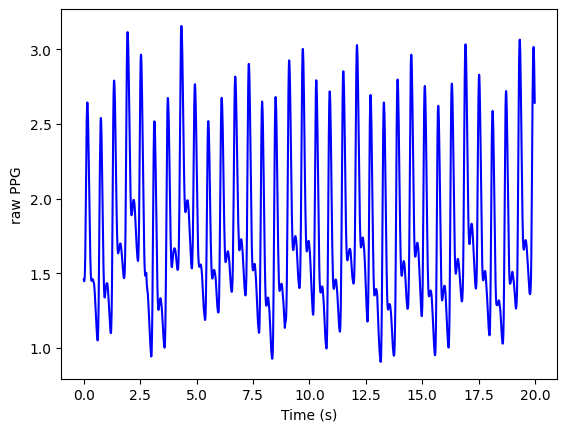

In [5]:
# import plotting package
from matplotlib import pyplot as plt

# setup figure
fig, ax = plt.subplots()

# create time vector
t = np.arange(0, len(signal.v))/signal.fs

# plot raw PPG_old signal
ax.plot(t, signal.v, color = 'blue')
ax.set(xlabel = 'Time (s)', ylabel = 'raw PPG_old')

# show plot
plt.show()

In [6]:
signal.filtering = True # whether or not to filter the PPG_old signal
signal.fL=0.5000001 # Lower cutoff frequency (Hz)
signal.fH=12 # Upper cutoff frequency (Hz)
signal.order=4 # Filter order
signal.sm_wins={'ppg':50,'vpg':10,'apg':10,'jpg':10} # smoothing windows in millisecond for the PPG_old, PPG_old', PPG_old", and PPG_old'"

prep = PP.Preprocess(fL=signal.fL, fH=signal.fH, order=signal.order, sm_wins=signal.sm_wins)
signal.ppg, signal.vpg, signal.apg, signal.jpg = prep.get_signals(s=signal)

In [7]:
# Initialise the correction for fiducial points
corr_on = ['on', 'dn', 'dp', 'v', 'w', 'f']
correction=pd.DataFrame()
correction.loc[0, corr_on] = True
signal.correction=correction

# Create a PPG_old class
s = PPG(signal)

In [8]:
fpex = FP.FpCollection(s=s)


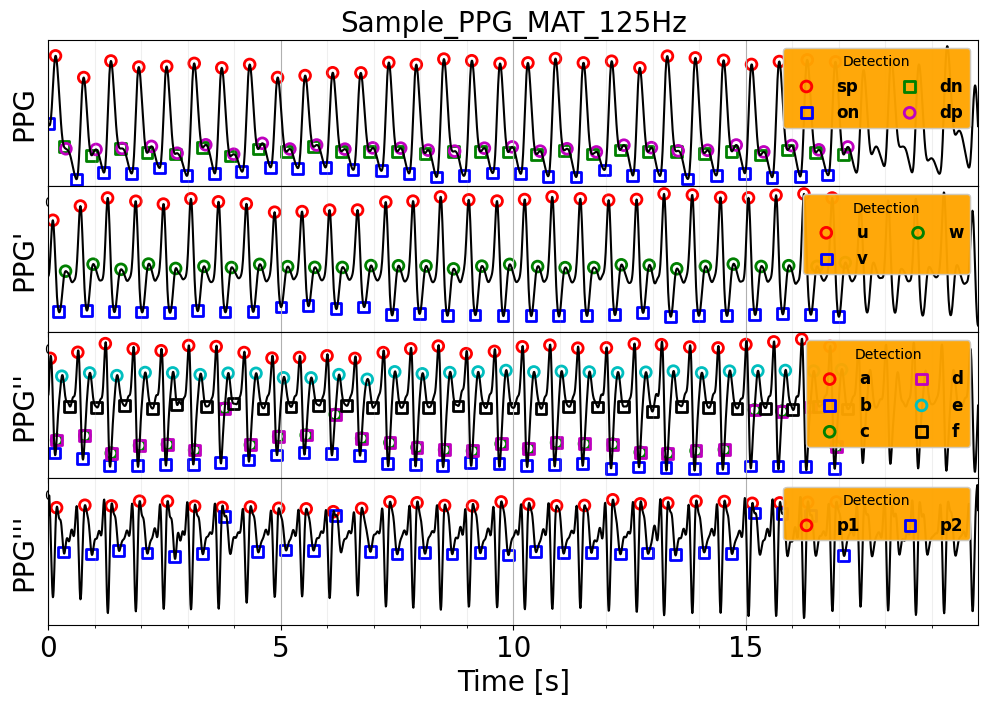

Figure has been saved in the "temp_dir/PPG_Figures/".


In [9]:
fiducials = fpex.get_fiducials(s=s)
# Create a fiducials class
fp = Fiducials(fp=fiducials)

# Plot fiducial points
plot_fiducials(s, fp, savingfolder, legend_fontsize=12)

In [10]:
bmex = BM.BmCollection(s=s, fp=fp)

# Extract biomarkers
bm_defs, bm_vals, bm_stats = bmex.get_biomarkers()
tmp_keys=bm_stats.keys()
print('Statistics of the biomarkers:')
for i in tmp_keys: print(i,'\n',bm_stats[i])

# Create a biomarkers class
bm = Biomarkers(bm_defs=bm_defs, bm_vals=bm_vals, bm_stats=bm_stats)

no more peaks
no more peaks
no more peaks
no more peaks
Statistics of the biomarkers:
ppg_sig 
                     Tpi       Tpp      Tsys      Tdia       Tsp       Tdp  \
Statistics                                                                  
mean           0.598571  0.599143  0.345714  0.183714  0.159143  0.414857   
median         0.600000  0.600000  0.344000  0.180000  0.160000  0.416000   
std            0.010913  0.006534  0.010110  0.013435  0.005792  0.016660   
percentile_25  0.592000  0.592000  0.336000  0.176000  0.158000  0.406000   
percentile_75  0.608000  0.602000  0.354000  0.192000  0.160000  0.424000   
iqr            0.016000  0.010000  0.018000  0.016000  0.002000  0.018000   
skew           0.155789 -0.194138  0.123521  1.051691 -0.399652 -0.426608   
kurtosis      -0.742472 -0.717518 -1.100450  0.890221  0.140338 -0.498165   
mad            0.008959  0.005163  0.008490  0.010571  0.004143  0.013878   

                 deltaT     Tsw10         Tsw25         

In [25]:
bm_stats['ppg_sig']

np.array(bm_stats['ppg_sig'])[0]

array([ 0.59857143,  0.59914286,  0.34571429,  0.18371429,  0.15914286,
        0.41485714,  0.25571429,  0.11457143,  0.09457143,  0.08657143,
        0.07057143,  0.05628571,  0.04742857,  0.02942857,  0.36457143,
        0.17314286,  0.12514286,  0.09571429,  0.07142857,  0.06      ,
        0.03542857,  0.47914286,  0.26771429,  0.21171429,  0.16628571,
        0.12771429,  0.10742857,  0.06485714,  1.50614004,  0.28367633,
        0.32491635, -0.0257478 ,  7.83178127,  4.82182399,  3.00995728])

In [11]:
# Save PPG_old struct, fiducial points, biomarkers
fp_new = Fiducials(fp.get_fp() + s.start_sig) # here the starting sample is added so that the results are relative to the start of the original signal (rather than the start of the analysed segment)
save_data(s=s, fp=fp_new, bm=bm, savingformat=savingformat, savingfolder=savingfolder)

Results have been saved into the ".".


{'data_struct_mat': '././PPG_struct/Sample_PPG_MAT_125Hz_data_btwn_0-15001.mat',
 'fiducials_csv': '././Fiducial_points/Sample_PPG_MAT_125Hz_Fiducials_btwn_0-15001.csv',
 'ppg_sig_vals_csv': '././Biomarker_vals/Sample_PPG_MAT_125Hz_ppg_sig_btwn_0-15001.csv',
 'ppg_sig_stats_csv': '././Biomarker_stats/Sample_PPG_MAT_125Hz_ppg_sig_btwn_0-15001.csv',
 'ppg_sig_defs_csv': '././Biomarker_defs/Sample_PPG_MAT_125Hz_ppg_sig_btwn_0-15001.csv',
 'sig_ratios_vals_csv': '././Biomarker_vals/Sample_PPG_MAT_125Hz_sig_ratios_btwn_0-15001.csv',
 'sig_ratios_stats_csv': '././Biomarker_stats/Sample_PPG_MAT_125Hz_sig_ratios_btwn_0-15001.csv',
 'sig_ratios_defs_csv': '././Biomarker_defs/Sample_PPG_MAT_125Hz_sig_ratios_btwn_0-15001.csv',
 'ppg_derivs_vals_csv': '././Biomarker_vals/Sample_PPG_MAT_125Hz_ppg_derivs_btwn_0-15001.csv',
 'ppg_derivs_stats_csv': '././Biomarker_stats/Sample_PPG_MAT_125Hz_ppg_derivs_btwn_0-15001.csv',
 'ppg_derivs_defs_csv': '././Biomarker_defs/Sample_PPG_MAT_125Hz_ppg_derivs_btwn_0